# 03 · Recalibration, impact and materiality
The production method is kept **exactly**: same pools, same 3-month hazard buckets, same credible-exposure tail, same monotonicity constraint. Only the evidence changes: development + monitoring (30,000 loans).

In [1]:
import sys; sys.path.insert(0, "../src")
from mu_catiii import *
from plots import *
pd.set_option("display.width", 160)
dev, mon, pd_old, lgd, ead = load_inputs()
pooled = pd.concat([dev, mon], ignore_index=True)
term_by_segment = pooled.groupby("segment")["term_months"].max().to_dict()

## 1. Method in one picture
A pool's lifetime PD is built from a **life table**: in each 3-month age bucket, hazard = defaults ÷ loans still at risk. Loans are only observed to 35 months, but a HELOC runs 120. Beyond the observed ages the curve needs a **tail hazard**: the pooled hazard of the last buckets until at least 300 loans of exposure are reached [JUDGMENT].

tail hazard: 0.0043 | lifetime PD (36m term): 0.1373

,bucket_start,bucket_end,n_at_risk,n_default,hazard
0,0,3,1989,11,0.0055
1,3,6,1978,19,0.0096
2,6,9,1959,28,0.0143
3,9,12,1931,35,0.0181
4,12,15,1896,24,0.0127
5,15,18,1236,31,0.0251
6,18,21,1205,26,0.0216
7,21,24,963,17,0.0177
8,24,27,712,10,0.0140
9,27,30,256,2,0.0078


Text(0.5, 1.0, 'credit_card | near-prime(640-679)')

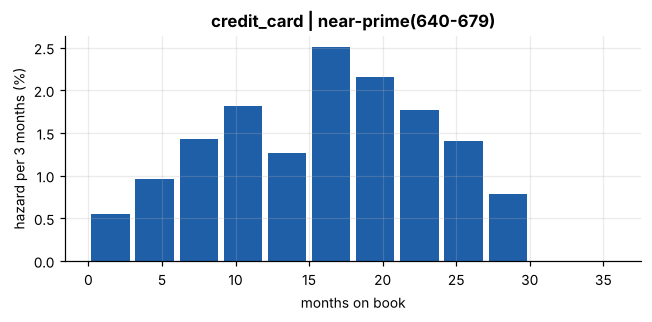

In [2]:
pid = 'credit_card | near-prime(640-679)'
sub = pooled[pooled.pool_id == pid]
edges = list(range(0, int(sub.months_on_book.max()) + BUCKET, BUCKET))
lt = life_table(sub, edges); display(lt)
print('tail hazard:', round(tail_hazard(lt), 4), '| lifetime PD (36m term):', round(pd_curve(lt, 36)[1], 4))
fig, ax = plt.subplots(figsize=(6, 3)); ax.bar(lt.bucket_start + 1.5, lt.hazard * 100, width=2.6, color=BLUE); ax.set_xlabel('months on book'); ax.set_ylabel('hazard per 3 months (%)'); ax.set_title(pid)

## 2. Re-estimate on pooled evidence

Simple mean of pool PD changes: 7.23%

,pool_id,PD_old,PD_lifetime_unconstrained,PD_new,change_pct,monotone_fix
0,auto_loan | subprime(<640),0.3012,0.3196,0.3196,0.0612,False
1,auto_loan | near-prime(640-679),0.2112,0.2195,0.2195,0.0392,False
2,auto_loan | prime(680-719),0.0715,0.0771,0.0771,0.0786,False
3,auto_loan | super-prime(720+),0.0512,0.0543,0.0543,0.0608,False
4,credit_card | subprime(<640),0.3023,0.3137,0.3137,0.0378,False
5,credit_card | near-prime(640-679),0.1136,0.1373,0.1373,0.2080,False
6,credit_card | prime(680-719),0.0759,0.0825,0.0825,0.0877,False
7,credit_card | super-prime(720+),0.0390,0.0426,0.0426,0.0933,False
8,heloc | subprime(<640),0.6186,0.5849,0.5849,-0.0545,False
9,heloc | near-prime(640-679),0.2736,0.2853,0.2853,0.0428,False


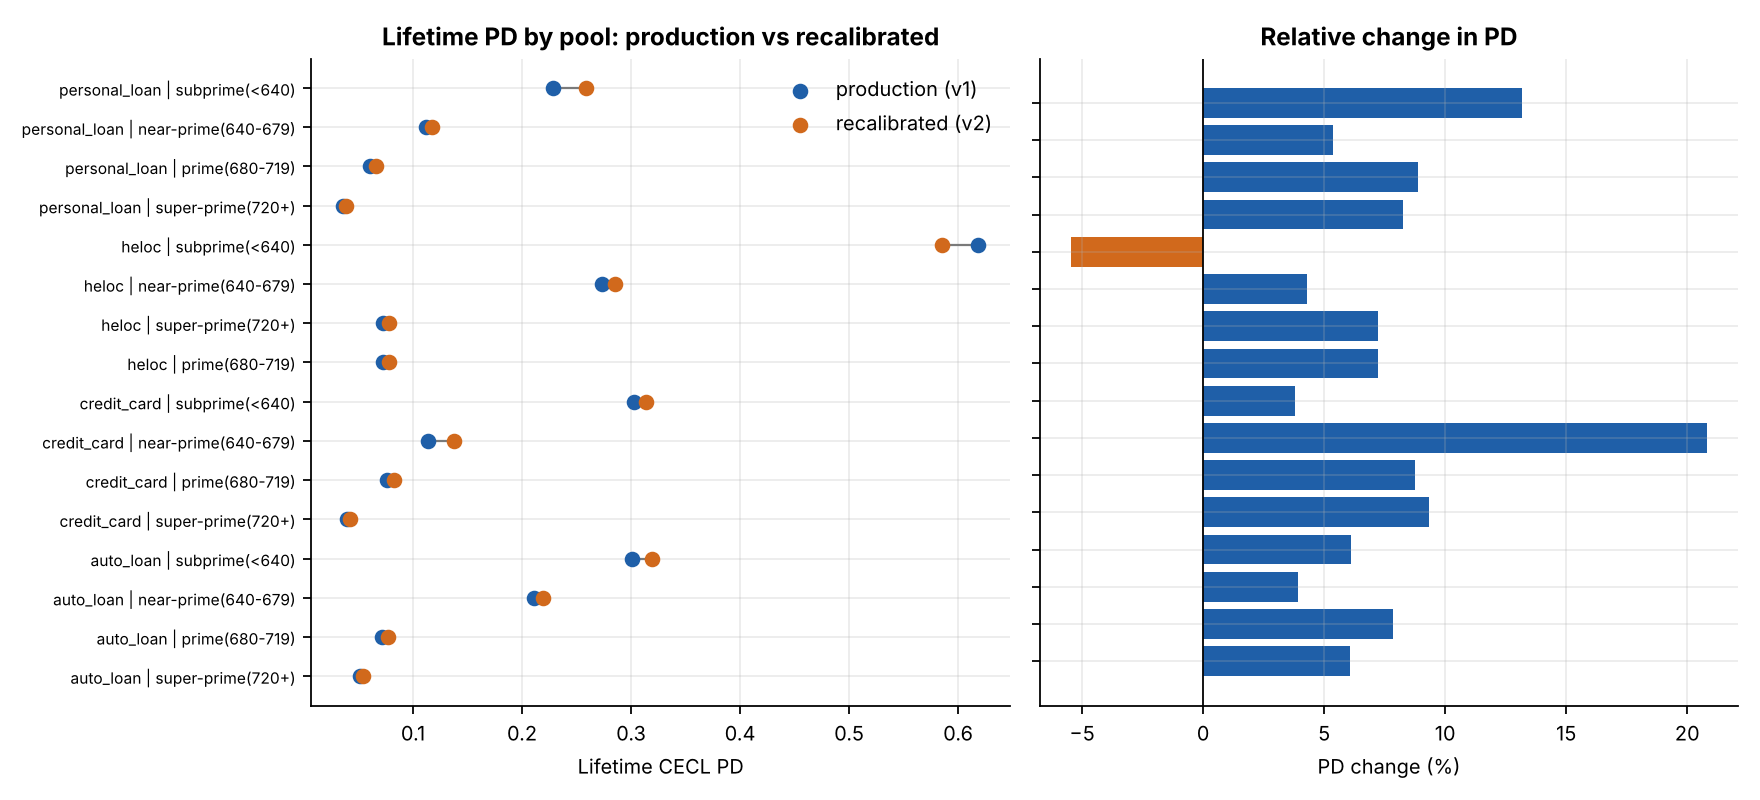

In [3]:
new = estimate_pd(pooled, term_by_segment)
old = pd_old[['pool_id','PD_lifetime_CECL']].rename(columns={'PD_lifetime_CECL':'PD_old'})
comp = old.merge(new[['pool_id','PD_lifetime_unconstrained','PD_lifetime']], on='pool_id').rename(columns={'PD_lifetime':'PD_new'})
comp['change_pct'] = comp.PD_new / comp.PD_old - 1
comp['monotone_fix'] = (comp.PD_new - comp.PD_lifetime_unconstrained).abs() > 1e-12
display(comp)
print('Simple mean of pool PD changes:', f'{comp.change_pct.mean():.2%}')
show_image(FIGS / 'fig06_pd_old_vs_new.png')

Two details. HELOC prime and super-prime come out with the same PD because the unconstrained estimates were reversed (prime 0.062 below super-prime 0.090, which would rank the better credit as riskier), so the isotonic step pools them at 0.0775; the production model had the same fix. And HELOC subprime goes **down** (−5.5%): its monitoring A/E was 0.92, in line with the noise story above.

## 3. Impact on Expected Loss
EL = PD × LGD × EAD$ × loans, with LGD and EAD unchanged (scope, see decision log).

Reference portfolio: $430,631,113
EL production : $19,813,798  (4.60% of funded)
EL recalibrated: $20,733,968  (4.81% of funded)
Change         : $920,170  (+4.64%)
Simple mean of pool PD changes (7.23%) is NOT the weighted change; the EL-weighted change is 4.64%.

,segment,exposure_funded,EL_old,EL_new,EL_change_pct,EL_old_pct_exposure,EL_new_pct_exposure
0,auto_loan,"148,432,864.3500","6,272,843.2849","6,624,021.6731",0.0560,0.0423,0.0446
1,credit_card,"42,633,468.0000","2,988,027.6149","3,278,647.4068",0.0973,0.0701,0.0769
2,heloc,"178,664,291.6300","7,692,664.7116","7,704,238.6520",0.0015,0.0431,0.0431
3,personal_loan,"60,900,488.6500","2,860,262.8603","3,127,060.6697",0.0933,0.0470,0.0513


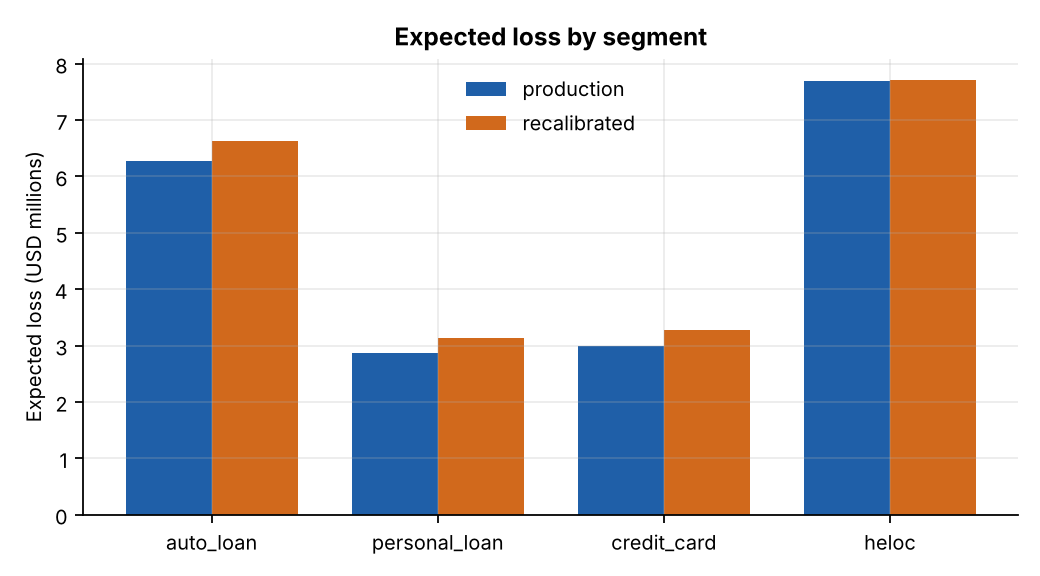

In [4]:
imp = pd.read_csv(TABLES / '03_el_impact_summary.csv').iloc[0]
print(f"Reference portfolio: ${imp.exposure_funded:,.0f}")
print(f"EL production : ${imp.EL_old:,.0f}  ({imp.EL_old_pct_exposure:.2%} of funded)")
print(f"EL recalibrated: ${imp.EL_new:,.0f}  ({imp.EL_new_pct_exposure:.2%} of funded)")
print(f"Change         : ${imp.delta_EL:,.0f}  ({imp.EL_change_pct:+.2%})")
print(f"Simple mean of pool PD changes ({imp.PD_change_simple_mean:.2%}) is NOT the weighted change; the EL-weighted change is {imp.EL_change_pct:.2%}.")
display(pd.read_csv(TABLES / '03_el_impact_by_segment.csv'))
show_image(FIGS / 'fig09_el_by_segment.png')

## 4. Materiality
The preliminary signal (25.1%, from raw default rates) was the trigger. The **final** number is the one that is sized on Expected Loss: **+4.64%**, below the 10% internal threshold [JUDGMENT]. The preliminary figure overstated the impact because the pooled recalibration dilutes the deteriorated period with the stable history.

In [5]:
display(pd.read_csv(TABLES / '03_materiality_bridge.csv'))

,step,value
0,Preliminary signal: simple mean of pool A/E minus 1 (raw rates),0.2512
1,"Recalibrated PD change, simple mean across pools",0.0723
2,"Recalibrated change in Expected Loss (PD x LGD x EAD, LGD/EAD unchanged)",0.0464
3,Internal materiality threshold [JUDGMENT],0.1000


## 5. Is +4.64% distinguishable from noise, and how sure are we?
Two different bootstraps answer two different questions.
* **Paired** (development and monitoring resampled separately; old = estimator on the development resample, new = estimator on the pooled resample): *is the change real?*
* **Unpaired** (production PD held fixed): *how uncertain is the new EL level?*

EL_change_unpaired   mean +3.67%  95% [-8.16%, +18.63%]  share above 10%: 18.0%
EL_change_paired     mean +5.23%  95% [+1.74%, +8.94%]  share above 10%: 1.0%

,segment,bootstrap_sd_EL_change
0,auto_loan,0.1119
1,credit_card,0.0624
2,heloc,0.1538
3,personal_loan,0.0523


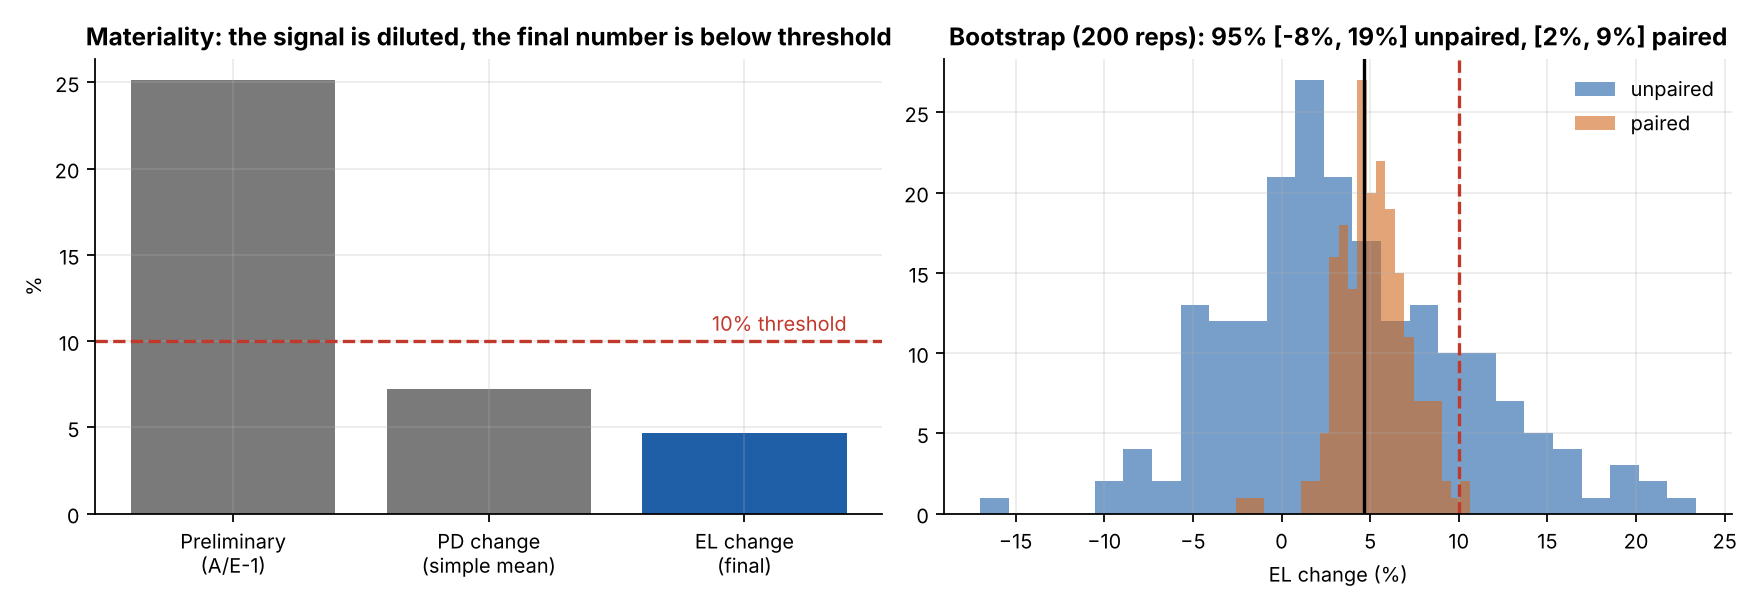

In [6]:
b = pd.read_csv(TABLES / '03_bootstrap_EL_change.csv'); import numpy as np
for c in b: print(f'{c:20s} mean {b[c].mean():+.2%}  95% [{np.percentile(b[c],2.5):+.2%}, {np.percentile(b[c],97.5):+.2%}]  share above 10%: {(b[c]>MATERIALITY_EL).mean():.1%}')
display(pd.read_csv(TABLES / '03_bootstrap_sd_by_segment.csv'))
show_image(FIGS / 'fig07_materiality_and_bootstrap.png')

The **change** is real and below 10% (paired interval about +1.7% to +8.9%). The **level** is much less certain (unpaired interval about −8% to +19%), and the uncertainty comes from the long-dated products (HELOC and auto) where most of the lifetime PD is extrapolated from a tail hazard. That belongs in the report, not under it.

## 6. What if the method were different?

,alternative,EL_change_pct,above_10pct_threshold
0,"Chosen: pooled dev+monitoring, tail 300, monotone",0.0464,False
1,Tail credible exposure = 150,0.0035,False
2,Tail credible exposure = 600,0.0396,False
3,No monotonicity constraint,0.0453,False
4,"Monitoring period only (29 months, 10,000 loans)",0.4736,True
5,"Development only (re-estimated, sanity check)",0.0000,False
6,Scalar: every PD x 1.251 (monitoring regime persists in full),0.2512,True
7,"Scalar: every PD x 1.55 (horizon-matched A/E, regime persists)",0.5457,True
8,Pool-specific scalar: PD x pool A/E (overfits noise),0.2007,True


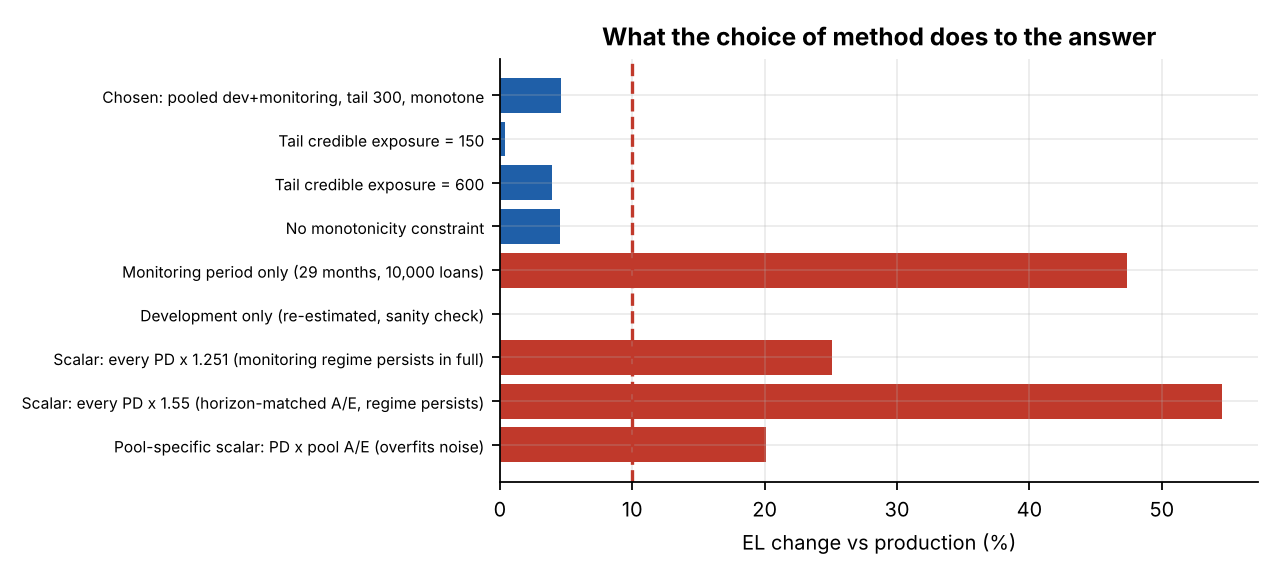

In [7]:
display(pd.read_csv(TABLES / '03_alternatives_sensitivity.csv'))
show_image(FIGS / 'fig08_method_sensitivity.png')

How to read the table:
* **Development only** returns exactly 0.00%: the code reproduces the production model, a necessary sanity check.
* **Monitoring only** gives +47%: a 29-month, single-regime sample, so it is a stress view and not an estimate.
* **Scalar 1.251** gives +25% (and a scalar at the horizon-matched 1.55 would give about +55%): it assumes the new regime lasts for the full life of every loan. The pooled method assumes the opposite end (history keeps two-thirds of the weight). The truth sits between them and is a **forecast question**, not a statistics question. CECL requires a reasonable and supportable forecast and a reversion approach; the Model Update recalibrates the model but does not replace that judgement. It is raised as a follow-up in the report.
* **Pool-specific scalar** gives +20% and overfits noise (see notebook 02).